# Chapter 2: The manifolds robots live on

This notebook reproduces every number in the chapter and gives you starting points for the exercises.
It needs only NumPy, SciPy and Matplotlib.

Conventions: $R \in \mathrm{SO}(3)$ maps body to world, $\dot R = R\,\Omega^\wedge$ with $\Omega$ in the body frame,
$q \in S^2$ with $\dot q = \omega \times q$ and $\omega \cdot q = 0$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

np.set_printoptions(precision=4, suppress=True)
E1, E2, E3 = np.eye(3)
I3 = np.eye(3)


def hat(x):
    return np.array([[0.0, -x[2], x[1]], [x[2], 0.0, -x[0]], [-x[1], x[0], 0.0]])


def vee(M):
    return np.array([M[2, 1], M[0, 2], M[1, 0]])


def expm_so3(phi):
    """Rodrigues' formula: exp(hat(phi))."""
    th = np.linalg.norm(phi)
    if th < 1e-12:
        return I3 + hat(phi)
    K = hat(phi / th)
    return I3 + np.sin(th) * K + (1 - np.cos(th)) * K @ K


def log_so3(R):
    """Rotation vector of R. Valid for rotation angles below pi."""
    th = np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1))
    if th < 1e-10:
        return vee(R - R.T) / 2
    return th / (2 * np.sin(th)) * vee(R - R.T)


def angle(R):
    return np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1))


def Rx(a):
    return expm_so3(a * E1)


def Rz(a):
    return expm_so3(a * E3)

## 1. The opening puzzle: a cable that stretches

Euler steps $q \leftarrow q + h\,(\omega \times q)$ at 100 Hz, with the cable swinging at 2 rad/s.

In [2]:
h, w, T = 0.01, 2.0, 10.0
q, om = E1.copy(), w * E3
lengths = [1.0]
for _ in range(round(T / h)):
    q = q + h * np.cross(om, q)
    lengths.append(np.linalg.norm(q))
print(f"cable length after {T:.0f} s: {lengths[-1]:.4f}")
print(f"predicted (1 + h^2 w^2)^(N/2): {(1 + h**2 * w**2) ** (T / h / 2):.4f}")

cable length after 10 s: 1.2214
predicted (1 + h^2 w^2)^(N/2): 1.2214


## 2. Curved sets and their velocities

The velocity of any curve on the sphere is perpendicular to $q$, and $\omega = q \times \dot q$ recovers it.

In [3]:
def curve(t):
    p = np.array([np.cos(t), np.sin(2 * t), 0.5 + 0.3 * t])
    return p / np.linalg.norm(p)


t0, d = 0.4, 1e-6
q0 = curve(t0)
qdot = (curve(t0 + d) - curve(t0 - d)) / (2 * d)
omega = np.cross(q0, qdot)
print("q . q_dot        =", f"{q0 @ qdot:.1e}")
print("omega x q - q_dot =", np.cross(omega, q0) - qdot)

q . q_dot        = 6.6e-11
omega x q - q_dot = [-0. -0. -0.]


The same for a rotation: $R^\top \dot R$ is skew-symmetric, so $\dot R = R\,\Omega^\wedge$.
The world-frame angular velocity is $\omega = R\,\Omega$, and $R\,x^\wedge R^\top = (Rx)^\wedge$.

In [4]:
rng = np.random.default_rng(0)
R = expm_so3(rng.normal(size=3))
Om = rng.normal(size=3)
Rdot = (R @ expm_so3(d * Om) - R @ expm_so3(-d * Om)) / (2 * d)
S = R.T @ Rdot
print("skew part check   :", f"{np.abs(S + S.T).max():.1e}")
print("body velocity     :", vee(S), "(should be", Om, ")")
print("world-frame omega :", vee(Rdot @ R.T), "= R Omega =", R @ Om)
x = rng.normal(size=3)
print("adjoint identity  :", f"{np.abs(R @ hat(x) @ R.T - hat(R @ x)).max():.1e}")

skew part check   : 8.7e-11
body velocity     : [ 0.1049 -0.5357  0.3616] (should be [ 0.1049 -0.5357  0.3616] )
world-frame omega : [ 0.3755 -0.4212  0.3321] = R Omega = [ 0.3755 -0.4212  0.3321]
adjoint identity  : 2.2e-16


**The phone on the turntable.** World angular velocity $(0, 0, 0.5)$. The gyroscope reads $\Omega = R^\top \omega$.

In [5]:
w_world = np.array([0.0, 0.0, 0.5])
print("phone flat    :", I3.T @ w_world)
print("phone upright :", Rx(np.pi / 2).T @ w_world)

phone flat    : [0.  0.  0.5]
phone upright : [0.  0.5 0. ]


## 3. From a velocity to a rotation: exp and log

In [6]:
phi = (np.pi / 2) * np.array([1.0, 1.0, 0.0]) / np.sqrt(2)
R_ex = expm_so3(phi)
print(R_ex)
print("matches scipy expm:", np.allclose(R_ex, expm(hat(phi))))
print("angle from trace  :", angle(R_ex), "(pi/2 =", np.pi / 2, ")")
print("log               :", log_so3(R_ex), "(theta u =", phi, ")")
u = np.array([0.0, 0.6, 0.8])
print("exp(pi u) == exp(-pi u):", np.allclose(expm_so3(np.pi * u), expm_so3(-np.pi * u)))

[[ 0.5     0.5     0.7071]
 [ 0.5     0.5    -0.7071]
 [-0.7071  0.7071  0.    ]]
matches scipy expm: True
angle from trace  : 1.5707963267948966 (pi/2 = 1.5707963267948966 )
log               : [1.1107 1.1107 0.    ] (theta u = [1.1107 1.1107 0.    ] )
exp(pi u) == exp(-pi u): True


On the sphere, $\exp_q(v) = \cos\|v\|\,q + \sin\|v\|\,v/\|v\|$.

In [7]:
def exp_s2(q, v):
    n = np.linalg.norm(v)
    return q if n < 1e-12 else np.cos(n) * q + np.sin(n) * v / n


v = np.array([0.3, 0.4, 0.0])            # tangent at the north pole
p = exp_s2(E3, v)
print("landed at", p, " norm", np.linalg.norm(p), " arc length", np.arccos(p @ E3))

landed at [0.2877 0.3835 0.8776]  norm 1.0  arc length 0.4999999999999999


## 4. Order matters: the bracket

The book: quarter turns about the desk's $x$ and $z$ axes, in both orders.
Turns about fixed axes multiply on the left.

In [8]:
A, B = Rx(np.pi / 2), Rz(np.pi / 2)
x_then_z, z_then_x = B @ A, A @ B
print("x then z: cover normal ->", x_then_z @ E3, " spine direction ->", x_then_z @ E2)
print("z then x: cover normal ->", z_then_x @ E3, " spine direction ->", z_then_x @ E2)
rel = x_then_z.T @ z_then_x
print(f"the two results differ by {np.degrees(angle(rel)):.1f} degrees about", log_so3(rel) / angle(rel))

x then z: cover normal -> [ 1. -0.  0.]  spine direction -> [-0.  0.  1.]
z then x: cover normal -> [ 0. -1.  0.]  spine direction -> [-1.  0.  0.]
the two results differ by 120.0 degrees about [-0.5774 -0.5774  0.5774]


Small rotations: the leftover of $\exp(\epsilon a^\wedge)\exp(\epsilon b^\wedge)\exp(-\epsilon a^\wedge)\exp(-\epsilon b^\wedge)$
is $\epsilon^2\, a \times b$ to leading order.

In [9]:
a, b = E1, E2
for eps in (0.1, 0.01):
    C = expm_so3(eps * a) @ expm_so3(eps * b) @ expm_so3(-eps * a) @ expm_so3(-eps * b)
    c = log_so3(C)
    print(f"eps = {eps}: leftover {np.linalg.norm(c):.6f} rad ({np.degrees(np.linalg.norm(c)):.3f} deg), "
          f"log / eps^2 = {c / eps**2}")
print("bracket identity:", np.allclose(hat(a) @ hat(b) - hat(b) @ hat(a), hat(np.cross(a, b))))

eps = 0.1: leftover 0.009992 rad (0.572 deg), log / eps^2 = [ 0.0499 -0.0499  0.9967]
eps = 0.01: leftover 0.000100 rad (0.006 deg), log / eps^2 = [ 0.005 -0.005  1.   ]
bracket identity: True


## 5. Position and attitude together: SE(3) and its adjoint

Twists are ordered $\zeta = (V, \Omega)$, linear part first.

In [10]:
def se3(R, x):
    X = np.eye(4)
    X[:3, :3], X[:3, 3] = R, x
    return X


def hat6(zeta):
    M = np.zeros((4, 4))
    M[:3, :3], M[:3, 3] = hat(zeta[3:]), zeta[:3]
    return M


def Ad(X):
    R, x = X[:3, :3], X[:3, 3]
    return np.block([[R, hat(x) @ R], [np.zeros((3, 3)), R]])


X = se3(R, rng.normal(size=3))
zeta = rng.normal(size=6)
lhs = X @ hat6(zeta) @ np.linalg.inv(X)
print("X zeta^ X^-1 = (Ad_X zeta)^ :", np.allclose(lhs, hat6(Ad(X) @ zeta)))

X zeta^ X^-1 = (Ad_X zeta)^ : True


## 6. A product manifold: quadrotor with a cable-suspended load

State $(x_L, q, R)$ on $\mathbb{R}^3 \times S^2 \times \mathrm{SO}(3)$, velocity $(v_L, \omega, \Omega)$.
The quadrotor position follows from $x_Q = x_L - l\,q$.

In [11]:
l = 1.0
xL, vL = np.array([2.0, 0.0, 1.0]), np.array([1.0, 0.0, 0.0])
q, om = -E3, np.array([0.5, 0.0, 0.0])
print("x_Q     =", xL - l * q)
print("x_Q dot =", vL - l * np.cross(om, q))


def step(state, vel, h):
    """One step on R^3 x S^2 x SO(3): Euler on the flat factor, exponential on the curved ones."""
    xL, q, R = state
    vL, om, Om = vel
    return xL + h * vL, expm_so3(h * om) @ q, R @ expm_so3(h * Om)


state = (xL, q, I3)
for _ in range(1000):
    state = step(state, (vL, om, np.array([0.3, -0.2, 0.5])), 0.01)
print("after 1000 steps: |q| - 1 =", f"{np.linalg.norm(state[1]) - 1:.1e}",
      " |R^T R - I| =", f"{np.linalg.norm(state[2].T @ state[2] - I3):.1e}")

x_Q     = [2. 0. 2.]
x_Q dot = [ 1.  -0.5  0. ]
after 1000 steps: |q| - 1 = -1.6e-15  |R^T R - I| = 1.2e-13


## 7. Stepping without falling off

A tumbling body, $\Omega(t) = (\cos t, \sin 0.7t, 0.5)$ rad/s, for 10 s at $h = 0.01$ s.

Euler:       |R^T R - I| = 0.157,  det R = 1.132
exponential: |R^T R - I| = 9.2e-15
attitude error, Omega at start of step: 0.287 deg
attitude error, Omega at midpoint:      0.00116 deg


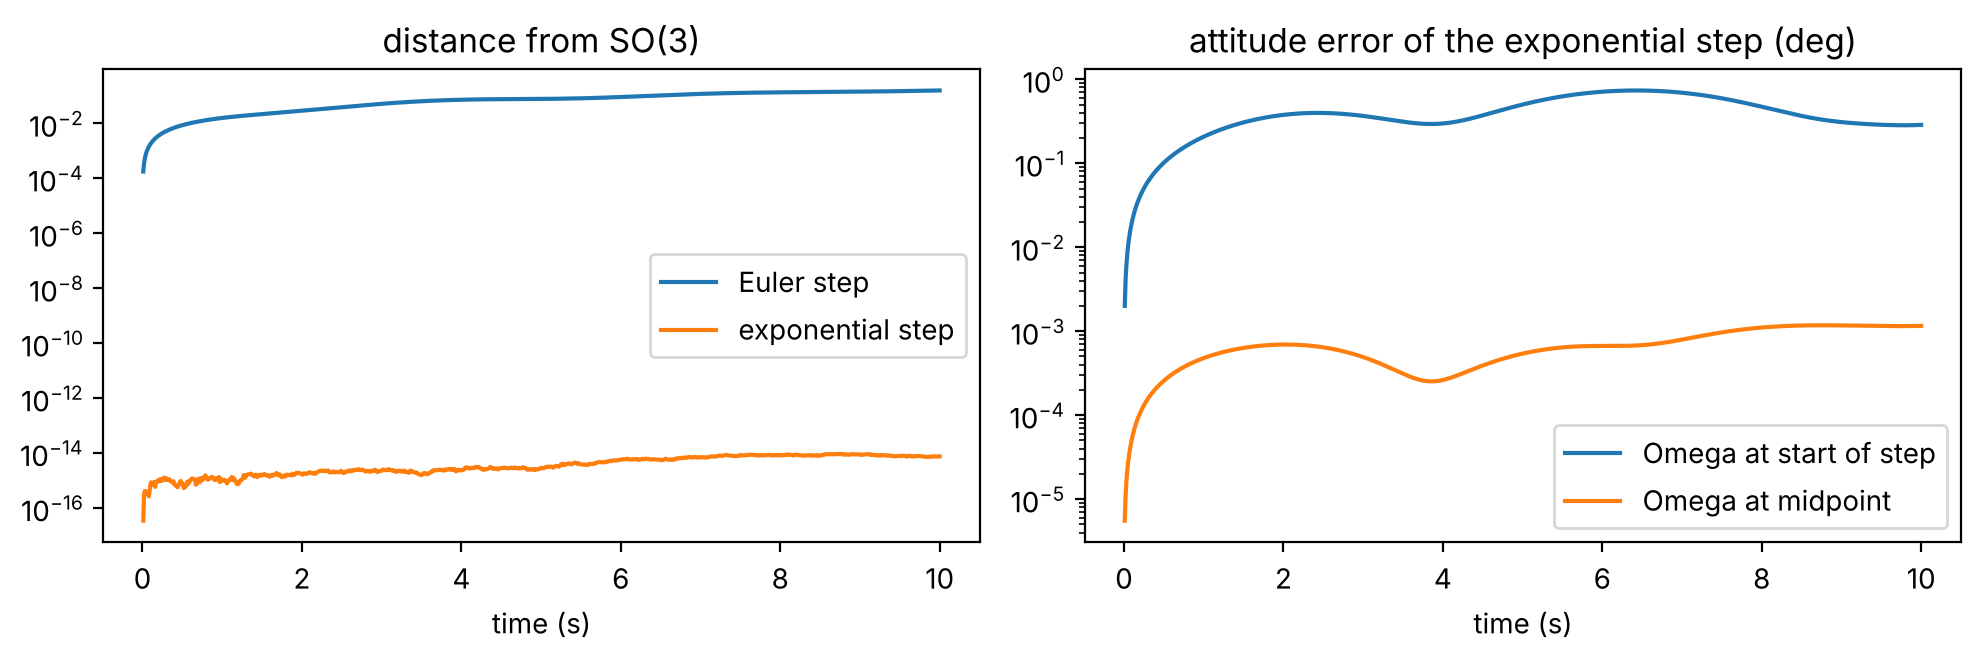

In [12]:
def Omega_of(t):
    return np.array([np.cos(t), np.sin(0.7 * t), 0.5])


def integrate(kind, h, T=10.0, midpoint=False):
    R, out = I3.copy(), [I3.copy()]
    for k in range(round(T / h)):
        Om = Omega_of((k + 0.5) * h) if midpoint else Omega_of(k * h)
        R = R + h * R @ hat(Om) if kind == "euler" else R @ expm_so3(h * Om)
        out.append(R)
    return np.array(out)


h = 0.01
t = np.arange(0, 10 + h / 2, h)
eu, ex, exm = integrate("euler", h), integrate("exp", h), integrate("exp", h, midpoint=True)
ref = integrate("exp", 1e-4, midpoint=True)[::100]
orth = lambda Rs: np.array([np.linalg.norm(M.T @ M - I3) for M in Rs])
err = lambda Rs: np.degrees([angle(A.T @ B) for A, B in zip(ref, Rs)])
print(f"Euler:       |R^T R - I| = {orth(eu)[-1]:.3f},  det R = {np.linalg.det(eu[-1]):.3f}")
print(f"exponential: |R^T R - I| = {orth(ex).max():.1e}")
print(f"attitude error, Omega at start of step: {err(ex)[-1]:.3f} deg")
print(f"attitude error, Omega at midpoint:      {err(exm)[-1]:.5f} deg")

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
axs[0].semilogy(t[1:], orth(eu)[1:], label="Euler step")
axs[0].semilogy(t[1:], np.maximum(orth(ex)[1:], 1e-17), label="exponential step")
axs[0].set_title("distance from SO(3)")
axs[1].semilogy(t[1:], np.maximum(err(ex)[1:], 1e-7), label="Omega at start of step")
axs[1].semilogy(t[1:], np.maximum(err(exm)[1:], 1e-7), label="Omega at midpoint")
axs[1].set_title("attitude error of the exponential step (deg)")
for ax in axs:
    ax.set_xlabel("time (s)")
    ax.legend()
plt.tight_layout()
plt.show()

Projection is the usual patch for a drifted matrix. The nearest rotation is the orthogonal polar factor.

In [13]:
U, _, Vt = np.linalg.svd(eu[-1])
R_proj = U @ Vt
print("projected matrix is a rotation:", np.allclose(R_proj.T @ R_proj, I3), f"det = {np.linalg.det(R_proj):.6f}")
print(f"but it is {np.degrees(angle(ref[-1].T @ R_proj)):.3f} deg from the true attitude")

projected matrix is a rotation: True det = 1.000000
but it is 0.295 deg from the true attitude


## Starting points for the exercises

**Exercise 2.1.** Change `h` in section 1 and compare with $\exp(\tfrac12 h\,\|\omega\|^2 t_f)$.

**Exercise 2.4.** Repeat the book experiment with 10° turns:

In [14]:
eps = np.radians(10)
C = Rx(eps) @ Rz(eps) @ Rx(-eps) @ Rz(-eps)
print("leftover:", log_so3(C), " prediction eps^2 (e1 x e3):", eps**2 * np.cross(E1, E3))

leftover: [ 0.0026 -0.0302 -0.0026]  prediction eps^2 (e1 x e3): [ 0.     -0.0305  0.    ]


**Exercise 2.6.** Order of accuracy of the exponential step. Extend the table and explain the two columns.

In [15]:
ref_end = integrate("exp", 1e-4, midpoint=True)[-1]
print("   h      start-of-step   midpoint   (errors in degrees)")
for hh in (0.02, 0.01, 0.005):
    e1 = np.degrees(angle(ref_end.T @ integrate("exp", hh)[-1]))
    e2 = np.degrees(angle(ref_end.T @ integrate("exp", hh, midpoint=True)[-1]))
    print(f"{hh:6.3f}   {e1:10.5f}   {e2:12.6f}")

   h      start-of-step   midpoint   (errors in degrees)
 0.020      0.57476       0.004628
 0.010      0.28684       0.001158
 0.005      0.14329       0.000293
